# Telco Customer Churn: Profiling, Cleaning & Business Insights

**Goal:** assess data quality, clean the data with documented decisions, and extract insights the business can act on to reduce churn.

**Dataset:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), a public IBM sample dataset (7,043 customers, 21 columns). It is synthetic sample data, not a real company's records.

**Structure:** (0) Executive summary → (1) Setup → (2) Profiling → (3) Cleaning decisions → (4) Validation → (5) Business insights → (6) Caveats & next steps

> Every number in the summary is computed in this notebook. A guard cell at the end fails if the data changes and the summary goes out of sync.

## 0) Executive Summary (non-technical)

**The situation.** The company has 7,043 customers and **26.5% of them have left**. Those customers represented about **30% of monthly revenue** (≈139K of 456K per month), so this is a material problem, not a rounding error.

**The data was almost clean.** There are no duplicate customers and no missing values except 11 brand-new customers who have not received a first bill yet. We set their lifetime billing to zero, because that is what actually happened.

**Who leaves? Five clear patterns:**

1. **Month-to-month contracts are the biggest risk.** 43% of month-to-month customers leave, versus only 3% of two-year customers.
2. **The first 6 months are critical.** About 53% of customers in their first 6 months leave, and 55% of *all* customers who ever left did so within their first year.
3. **Payment method matters.** Customers paying by electronic check leave at 45%, versus 15–17% for customers on automatic payments.
4. **Fiber customers pay more and leave more.** Fiber churn is 42%, and 55% for Fiber customers on month-to-month contracts. This suggests customers feel the price is not matched by the value.
5. **Protection and support services keep customers.** Customers with none of the four add-ons (Security, Backup, Device Protection, Tech Support) leave at 57%. Customers with all four leave at 5%.

**Recommended actions.** (a) Offer annual-contract upgrades during the first 6 months, (b) incentivise automatic payment, (c) bundle free Tech Support / Security trials into Fiber plans, (d) build an onboarding programme for new customers.

**Important caveat.** These are **associations, not proven causes**. For example, customers who are already unsure may simply choose monthly contracts. Each action above should be tested on a small group (A/B test) before a full rollout.

## 1) Setup & Load

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency, mannwhitneyu

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
RNG_SEED = 42

# If you know the file location, set it here, e.g.:
# DATA_PATH = "C:/Users/me/Downloads/WA_Fn-UseC_-Telco-Customer-Churn.csv"
DATA_PATH = None

def find_data(explicit=None, pattern="*Telco-Customer-Churn*.csv"):
    """Locate the CSV: explicit path first, then common folders (newest match wins)."""
    if explicit:
        p = Path(explicit).expanduser()
        if p.is_file():
            return p
        raise FileNotFoundError(f"DATA_PATH does not exist: {p}")
    home = Path.home()
    search_dirs = [Path.cwd(), Path.cwd() / "data", Path.cwd().parent,
                   home / "Downloads", home / "Desktop", home / "Documents"]
    for d in search_dirs:
        if d.is_dir():
            hits = sorted(d.glob(pattern), key=lambda f: f.stat().st_mtime, reverse=True)
            if hits:
                return hits[0]
    raise FileNotFoundError(
        "Dataset not found. Searched: " + " | ".join(map(str, search_dirs)) +
        ". Place the CSV next to this notebook (or in ./data) or set DATA_PATH.")

DATA_FILE = find_data(DATA_PATH)
print("Loading:", DATA_FILE)
raw = pd.read_csv(DATA_FILE)
print(raw.shape)
raw.head()

Loading: /home/claude/work/github/WA_Fn-UseC_-Telco-Customer-Churn.csv
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2) Profiling

### 2.1 Schema and data types

In [2]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_null": raw.isna().sum(),
    "n_blank_str": raw.apply(lambda s: s.astype(str).str.strip().eq("").sum()),
    "sample_values": raw.apply(lambda s: list(s.dropna().unique()[:4])),
})
profile

,dtype,n_unique,n_null,n_blank_str,sample_values
customerID,str,7043,0,0,"[7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW]"
gender,str,2,0,0,"[Female, Male]"
SeniorCitizen,int64,2,0,0,"[0, 1]"
Partner,str,2,0,0,"[Yes, No]"
Dependents,str,2,0,0,"[No, Yes]"
tenure,int64,73,0,0,"[1, 34, 2, 45]"
PhoneService,str,2,0,0,"[No, Yes]"
MultipleLines,str,3,0,0,"[No phone service, No, Yes]"
InternetService,str,3,0,0,"[DSL, Fiber optic, No]"
OnlineSecurity,str,3,0,0,"[No, Yes, No internet service]"


**Findings**
- `TotalCharges` is stored as a **string** although it is numeric, because some values are blank strings. This is why `isna()` reports 0 missing values, which is **misleading**.
- `SeniorCitizen` is an int (0/1) while the other binary columns use Yes/No, an inconsistent encoding.
- `customerID` is an identifier, not a feature.

### 2.2 Missing values (real ones, not just NaN)

In [3]:
tc_numeric = pd.to_numeric(raw["TotalCharges"], errors="coerce")
bad_tc = raw[tc_numeric.isna()]
print("TotalCharges non-numeric rows:", len(bad_tc))
bad_tc[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

TotalCharges non-numeric rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [4]:
# Is the missingness random? Check the tenure of those rows against the rest.
print("tenure of missing rows:", bad_tc["tenure"].unique())
print("customers with tenure == 0 overall:", (raw["tenure"] == 0).sum())

tenure of missing rows: [0]
customers with tenure == 0 overall: 11


**Finding:** all 11 rows have `tenure = 0`, and they are the *only* customers with `tenure = 0`. This is **not random**: they are new customers who have not yet been billed. The missing value has a clear business meaning.

### 2.3 Duplicates

In [5]:
print("Full-row duplicates:           ", raw.duplicated().sum())
print("Duplicate customerID:          ", raw["customerID"].duplicated().sum())
print("Duplicates ignoring customerID:", raw.drop(columns="customerID").duplicated().sum())

Full-row duplicates:            0
Duplicate customerID:           0
Duplicates ignoring customerID: 22


- No full-row duplicates and no repeated IDs.
- Some rows are identical once the ID is ignored. These are **different customers with the same profile** (common, simple plans), so they are **not duplicates** and are kept. Removing them would under-weight real customer segments.

### 2.4 Categorical columns: inconsistent labels and whitespace

In [6]:
cat_cols = [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype) in ("str", "string")]
cat_cols = [c for c in cat_cols if c not in ("customerID", "TotalCharges")]
for c in cat_cols:
    vals = {k: int(v) for k, v in raw[c].value_counts().items()}
    ws = raw[c].astype(str).ne(raw[c].astype(str).str.strip()).sum()
    print(f"{c:18s} {vals}  | whitespace issues: {ws}")

gender             {'Male': 3555, 'Female': 3488}  | whitespace issues: 0
Partner            {'No': 3641, 'Yes': 3402}  | whitespace issues: 0
Dependents         {'No': 4933, 'Yes': 2110}  | whitespace issues: 0
PhoneService       {'Yes': 6361, 'No': 682}  | whitespace issues: 0
MultipleLines      {'No': 3390, 'Yes': 2971, 'No phone service': 682}  | whitespace issues: 0
InternetService    {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}  | whitespace issues: 0
OnlineSecurity     {'No': 3498, 'Yes': 2019, 'No internet service': 1526}  | whitespace issues: 0
OnlineBackup       {'No': 3088, 'Yes': 2429, 'No internet service': 1526}  | whitespace issues: 0
DeviceProtection   {'No': 3095, 'Yes': 2422, 'No internet service': 1526}  | whitespace issues: 0
TechSupport        {'No': 3473, 'Yes': 2044, 'No internet service': 1526}  | whitespace issues: 0
StreamingTV        {'No': 2810, 'Yes': 2707, 'No internet service': 1526}  | whitespace issues: 0
StreamingMovies    {'No': 2785, 'Yes': 2732, '

- No typos or stray whitespace in any category.
- `"No internet service"` and `"No phone service"` are **not missing values**. They are structural: the customer has no underlying service, so the add-on cannot exist.

### 2.5 Numeric distributions and outliers

In [7]:
num = raw[["tenure", "MonthlyCharges"]].assign(TotalCharges=tc_numeric)
desc = num.describe().T
desc["skew"] = num.skew()

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

desc["iqr_outliers"] = [iqr_outliers(num[c].dropna()) for c in num]
desc["z>3"] = [int((np.abs((num[c] - num[c].mean()) / num[c].std()) > 3).sum()) for c in num]
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,iqr_outliers,z>3
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24,0,0
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22,0,0
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,0.96,0,0


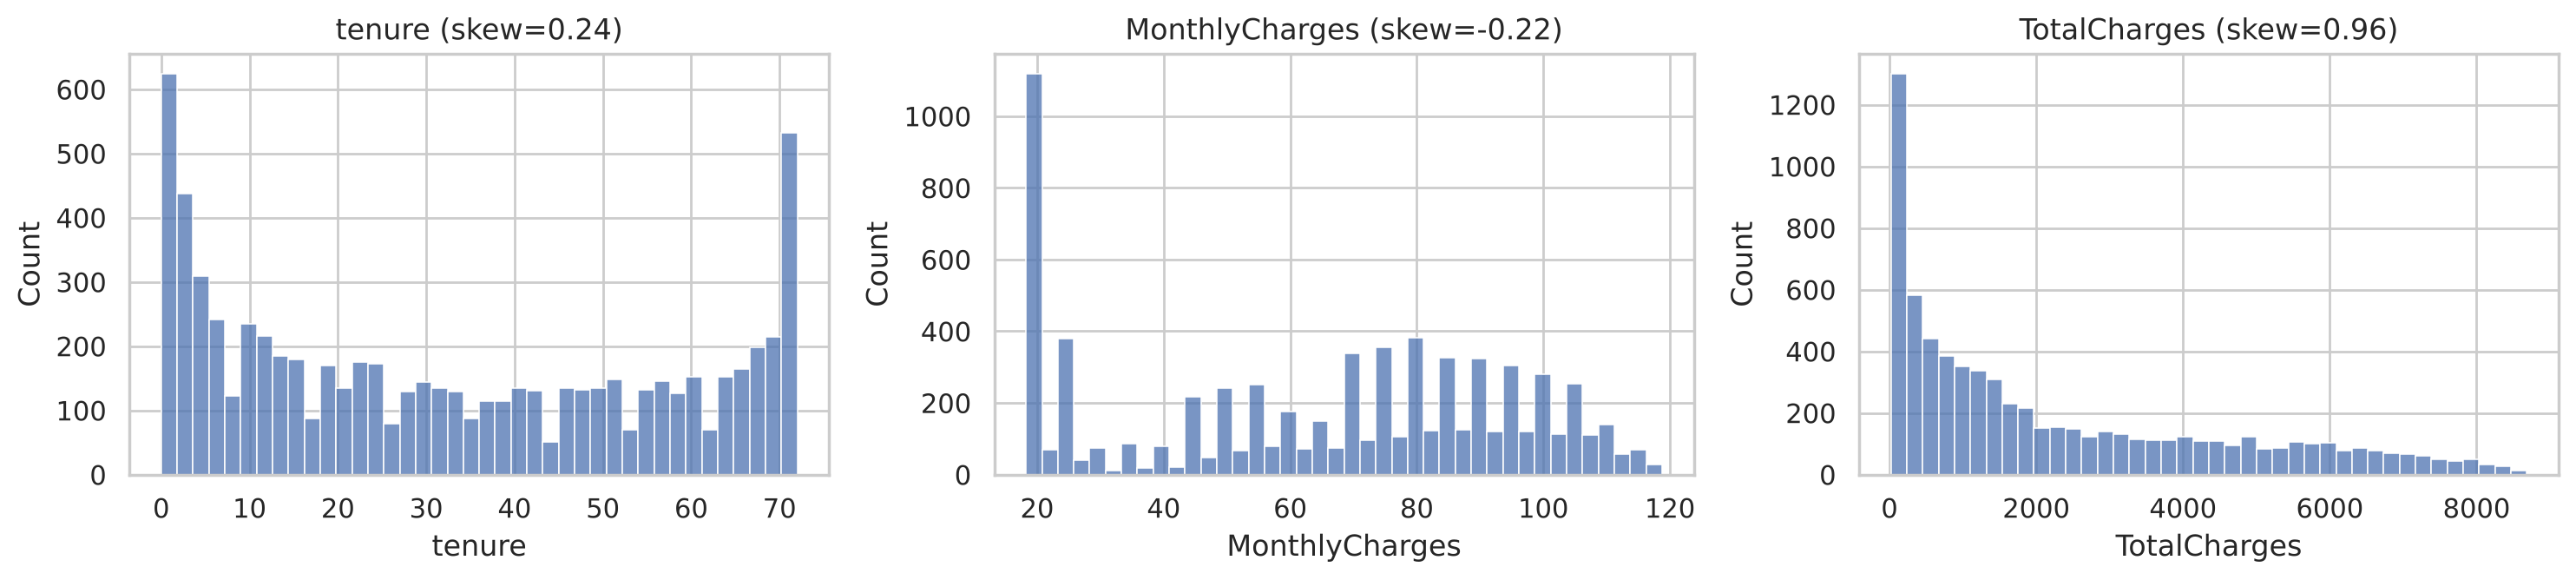

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, num.columns):
    sns.histplot(num[c].dropna(), bins=40, ax=ax)
    ax.set_title(f"{c} (skew={num[c].skew():.2f})")
plt.tight_layout(); plt.show()

In [9]:
# Consistency check: is TotalCharges roughly tenure x MonthlyCharges?
expected = raw["tenure"] * raw["MonthlyCharges"]
rel_gap = ((tc_numeric - expected).abs() / expected.replace(0, np.nan))
print(rel_gap.describe().round(3))
print("rows with >30% gap:", int((rel_gap > 0.30).sum()))

count    7032.000
mean        0.032
std         0.040
min         0.000
25%         0.007
50%         0.020
75%         0.042
max         0.573
dtype: float64
rows with >30% gap: 13


**Outlier findings**
- **Zero outliers** by both the IQR rule and the z-score in all three columns. The extremes (tenure 72, monthly charge 118.75) are plausible business values.
- `tenure` is bimodal: one peak for new customers and one at 72, which suggests the data is **capped at 72 months**.
- `TotalCharges` is right-skewed (≈0.96) because it is roughly tenure × price.
- Consistency check: the average gap between `TotalCharges` and `tenure × MonthlyCharges` is only about 2–3%, which is normal (plan or price changes over time). A small number of rows have a large gap. There is no evidence they are wrong, so they are flagged rather than removed.

## 3) Cleaning: decisions and rationale

| # | Issue | Decision | Why |
|---|---|---|---|
| 1 | `TotalCharges` is a string with 11 blanks | Convert to float; the 11 blanks become **0** (not the median) | All 11 have `tenure = 0`, i.e. not billed yet. A median (~1,400) would invent revenue for customers with zero months of service and break the `Total ≈ tenure × Monthly` relationship. |
| 2 | Those 11 rows | **Keep them** and add flag `is_new_customer` | They are 0.16% of the data; dropping them would remove a real segment (brand-new customers). The flag lets any downstream model treat them as a special case. |
| 3 | Duplicates | Do nothing | No full-row duplicates or repeated IDs; identical profiles without ID are different customers. |
| 4 | `SeniorCitizen` is 0/1 while others are Yes/No | Map to Yes/No | Consistent encoding for analysis and reporting. |
| 5 | `Churn` is Yes/No | Add numeric target `churn` (0/1) | Makes rates and modelling straightforward. |
| 6 | `No internet service` / `No phone service` | **Keep as separate categories** for analysis | Different meaning from "No" (the customer cannot have the service at all). Merging them with "No" would distort the apparent churn rate of "No". For modelling they can be merged because `InternetService` already carries that information. |
| 6b | 13 rows where `TotalCharges` deviates >30% from `tenure × Monthly` | Flag as `charges_inconsistent`, do not delete | No evidence they are wrong (could be plan changes), but the flag allows a sensitivity check. |
| 7 | Outliers | **No capping, no removal** | There are no statistical outliers and the extremes are real values. |
| 8 | `TotalCharges` is skewed | Leave as is; `log1p` **only** if a linear model is used | Descriptive analysis uses medians, which are robust to skew; tree models do not need the transform. |
| 9 | `customerID` | Use as index, exclude from features | It is an identifier with no predictive value and risks overfitting. |
| 10 | Categorical dtypes | Convert to `category` | Lower memory and a clearer schema. |

In [10]:
def clean(df_raw: pd.DataFrame) -> pd.DataFrame:
    df = df_raw.copy()
    # (1)+(2) TotalCharges: blank -> 0 for tenure==0 customers only
    tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
    assert df.loc[tc.isna(), "tenure"].eq(0).all(), "Unexpected missing TotalCharges for tenure>0"
    df["TotalCharges"] = tc.fillna(0.0)
    df["is_new_customer"] = (df["tenure"] == 0).astype(int)
    # (6b) flag, not drop, rows where TotalCharges deviates >30% from tenure x MonthlyCharges
    exp = df["tenure"] * df["MonthlyCharges"]
    df["charges_inconsistent"] = (((df["TotalCharges"] - exp).abs() / exp.replace(0, np.nan)) > 0.30).astype(int)
    # (4) consistent binary encoding
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
    # (5) numeric target
    df["churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)
    # (9) id as index
    df = df.set_index("customerID")
    # (10) categorical dtypes
    for c in df.columns:
        if df[c].dtype == object or str(df[c].dtype) in ("str", "string"):
            df[c] = df[c].astype("category")
    return df

df = clean(raw)
df.info()

<class 'pandas.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   gender                7043 non-null   category
 1   SeniorCitizen         7043 non-null   category
 2   Partner               7043 non-null   category
 3   Dependents            7043 non-null   category
 4   tenure                7043 non-null   int64   
 5   PhoneService          7043 non-null   category
 6   MultipleLines         7043 non-null   category
 7   InternetService       7043 non-null   category
 8   OnlineSecurity        7043 non-null   category
 9   OnlineBackup          7043 non-null   category
 10  DeviceProtection      7043 non-null   category
 11  TechSupport           7043 non-null   category
 12  StreamingTV           7043 non-null   category
 13  StreamingMovies       7043 non-null   category
 14  Contract              7043 non-null   category
 15  Paper

## 4) Validation after cleaning

Generated results are candidates, not facts. These checks verify the cleaning did what it claims:

In [11]:
assert df.shape[0] == raw.shape[0], "lost rows"
assert df.index.is_unique
assert df.isna().sum().sum() == 0, "nulls remain"
assert df["TotalCharges"].dtype.kind == "f"
assert (df.loc[df.tenure == 0, "TotalCharges"] == 0).all()
assert (df["TotalCharges"] >= 0).all() and (df["MonthlyCharges"] > 0).all()
assert set(df["churn"].unique()) == {0, 1}
assert df["charges_inconsistent"].sum() == 13
assert set(df["SeniorCitizen"].cat.categories) == {"No", "Yes"}
# the churn target must be unchanged by cleaning
assert df["churn"].sum() == (raw["Churn"] == "Yes").sum()
print("All validation checks passed")

All validation checks passed


## 5) Business Insights

Each insight includes the number, a statistical test showing it is not chance, and a suggested action.

In [12]:
BASE = df["churn"].mean()

def churn_table(col):
    t = df.groupby(col, observed=True)["churn"].agg(churn_rate="mean", customers="size")
    t["lift_vs_avg"] = t["churn_rate"] / BASE
    p = chi2_contingency(pd.crosstab(df[col], df["churn"]))[1]
    return t.sort_values("churn_rate", ascending=False).round(3), p

def bar(t, title, ax=None):
    ax = ax or plt.gca()
    sns.barplot(x=t.index.astype(str), y=t["churn_rate"] * 100, ax=ax, color="#4C72B0")
    ax.axhline(BASE * 100, ls="--", c="red", lw=1, label=f"avg {BASE:.1%}")
    ax.set_ylabel("churn %"); ax.set_xlabel(""); ax.set_title(title); ax.legend()
    for i, v in enumerate(t["churn_rate"]):
        ax.text(i, v * 100 + 1, f"{v:.0%}", ha="center")

mrr_total = df["MonthlyCharges"].sum()
mrr_lost = df.loc[df.churn == 1, "MonthlyCharges"].sum()
print(f"Overall churn: {BASE:.1%}  |  Monthly revenue from churned customers: {mrr_lost:,.0f} of {mrr_total:,.0f} ({mrr_lost/mrr_total:.1%})")

Overall churn: 26.5%  |  Monthly revenue from churned customers: 139,131 of 456,117 (30.5%)


### Insight 1: Contract type is the strongest predictor

,churn_rate,customers,lift_vs_avg
Contract,,,
Month-to-month,0.427,3875,1.609
One year,0.113,1473,0.425
Two year,0.028,1695,0.107


chi2 p-value = 5.86e-258


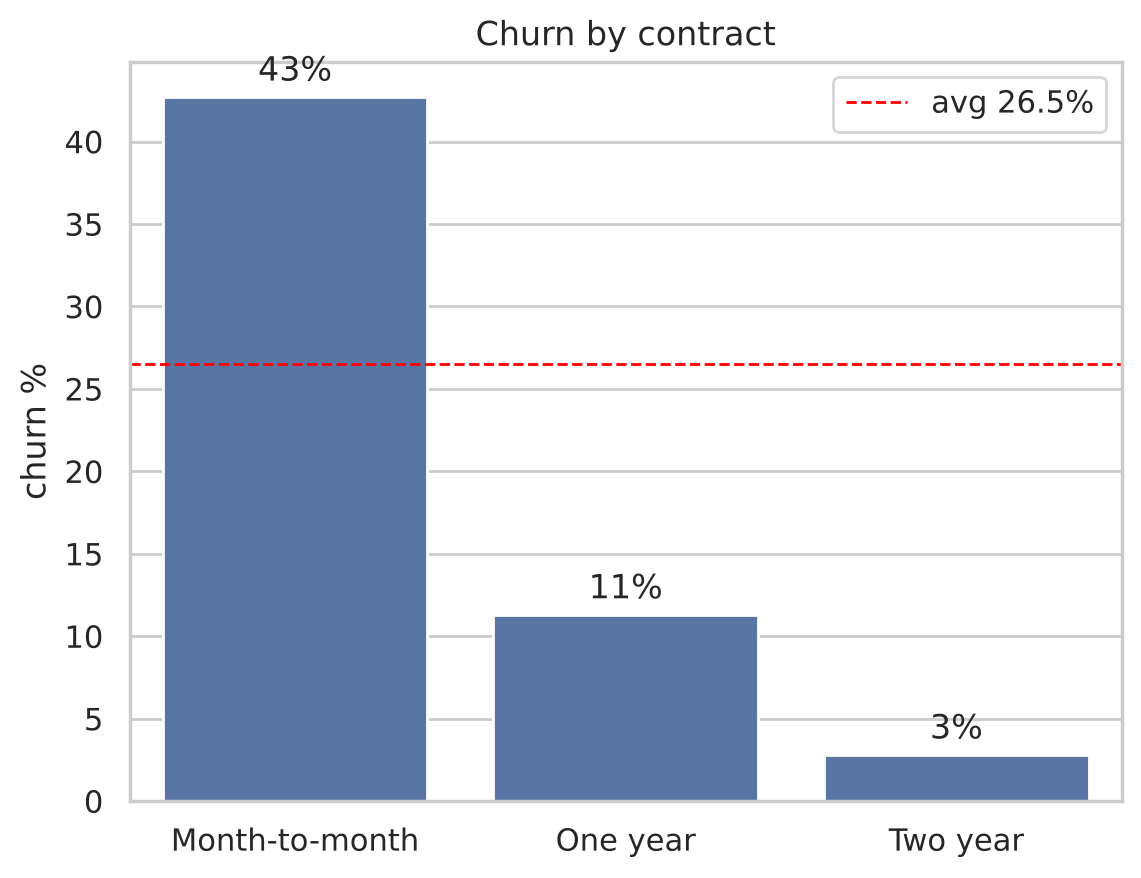

In [13]:
t, p = churn_table("Contract"); display(t); print(f"chi2 p-value = {p:.2e}")
bar(t, "Churn by contract"); plt.show()

Month-to-month churn is about **43%** versus about **3%** for two-year contracts (more than 15x), and month-to-month is also the largest segment (55% of customers).

**Action:** offer an annual-contract upgrade (discount or a free month), targeted at month-to-month customers, especially in their first year.

### Insight 2: The first 6 months are the danger zone

,churn_rate,customers,lift_vs_avg
tenure_band,,,
0-6m,0.529,1481,1.995
7-12m,0.359,705,1.352
13-24m,0.287,1024,1.082
25-48m,0.204,1594,0.768
49-72m,0.095,2239,0.358


chi2 p-value = 2.00e-199
Share of all churners who left within 12 months: 55.5%


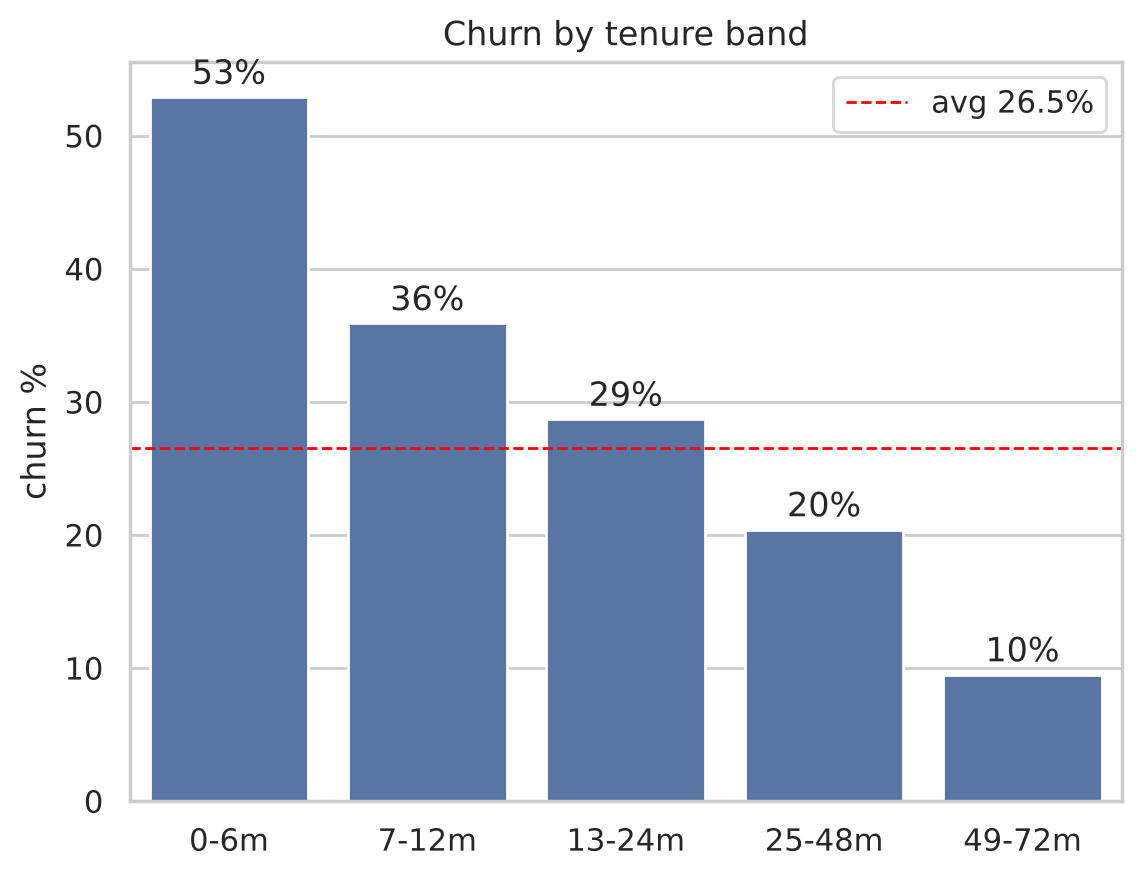

In [14]:
df["tenure_band"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                          labels=["0-6m", "7-12m", "13-24m", "25-48m", "49-72m"])
t, p = churn_table("tenure_band"); t = t.sort_index(); display(t); print(f"chi2 p-value = {p:.2e}")
share_first_year = (df.loc[df.churn == 1, "tenure"] <= 12).mean()
print(f"Share of all churners who left within 12 months: {share_first_year:.1%}")
bar(t, "Churn by tenure band"); plt.show()

About **53%** of customers in their first 6 months leave, and more than **half** of all churners leave within the first year. Risk falls steadily with tenure.

**Action:** an onboarding programme (welcome call, check-ins at month 1 and 3, fast resolution of the first issue). Any improvement here touches the largest block of churn.

### Insight 3: Payment method

,churn_rate,customers,lift_vs_avg
PaymentMethod,,,
Electronic check,0.453,2365,1.707
Mailed check,0.191,1612,0.720
Bank transfer (automatic),0.167,1544,0.630
Credit card (automatic),0.152,1522,0.574


chi2 p-value = 3.68e-140


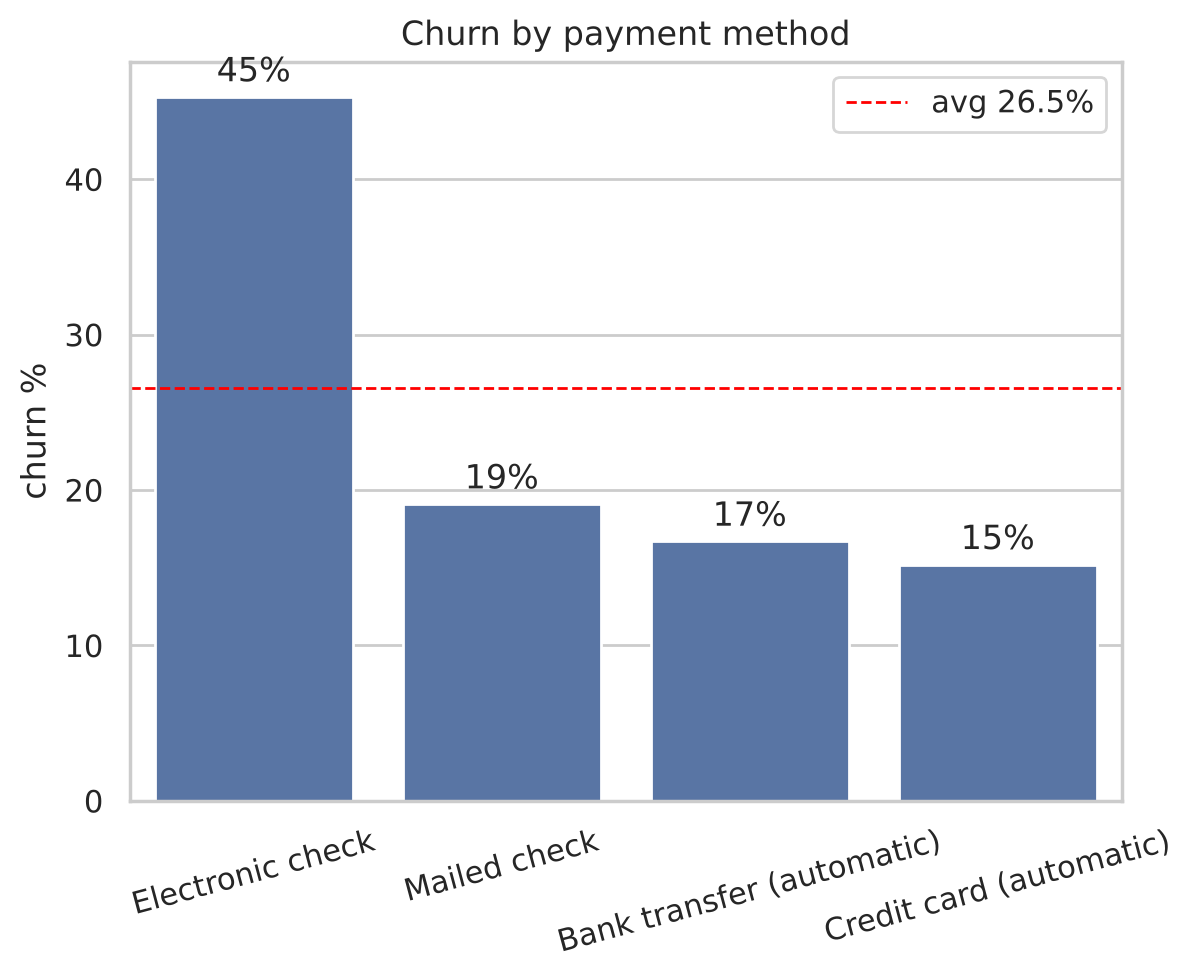

In [15]:
t, p = churn_table("PaymentMethod"); display(t); print(f"chi2 p-value = {p:.2e}")
bar(t, "Churn by payment method"); plt.xticks(rotation=15); plt.show()

Electronic-check churn is about **45%** versus about **15–17%** for automatic payments (bank transfer or credit card). Paying manually forces a monthly "decision to pay", which is a friction point.

**Action:** a small monthly incentive to switch to auto-pay. Note that part of the effect may be selection (hesitant customers do not link a card), so this needs an A/B test.

### Insight 4: Fiber customers pay more and leave more

,churn_rate,customers,lift_vs_avg
InternetService,,,
Fiber optic,0.419,3096,1.579
DSL,0.190,2421,0.714
No,0.074,1526,0.279


chi2 p-value = 9.57e-160
Fiber + Month-to-month: 2,128 customers, churn = 54.6%
Median monthly charge - churned: 79.65 vs stayed: 64.43 (Mann-Whitney p = 3.3e-54)


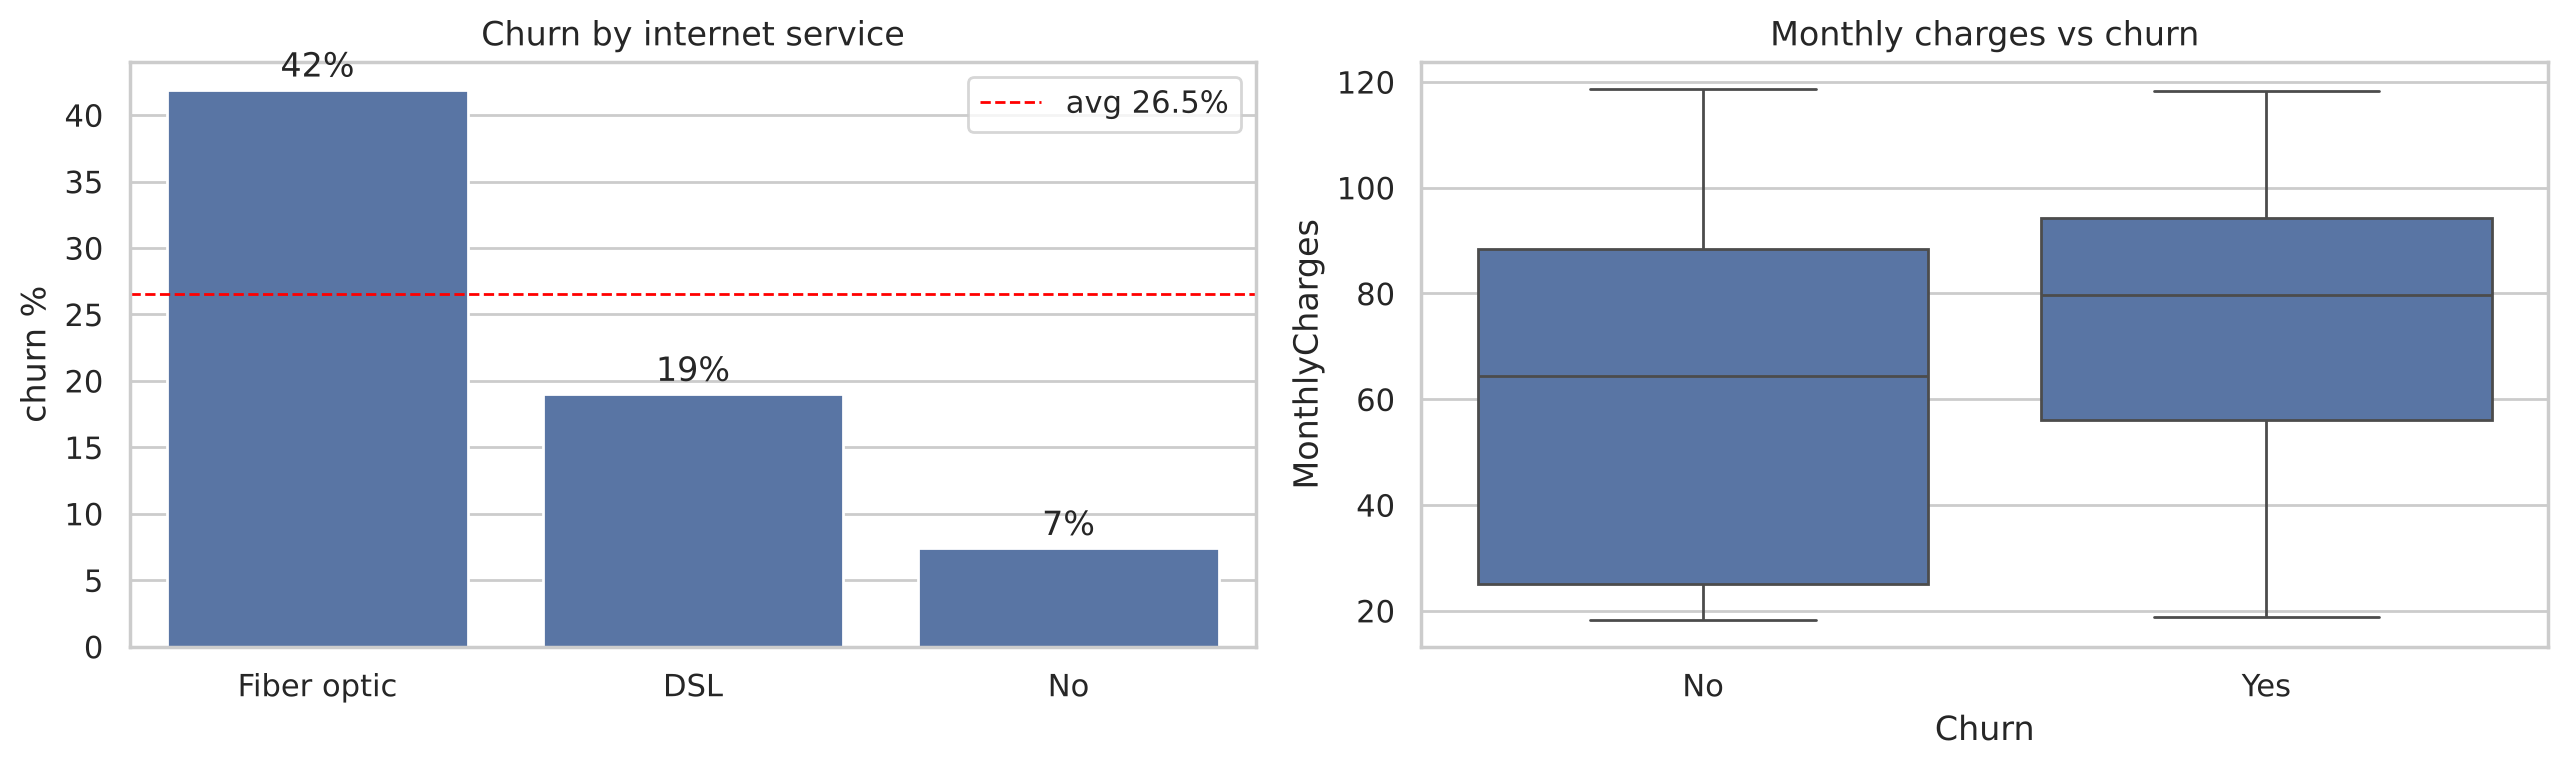

In [16]:
t, p = churn_table("InternetService"); display(t); print(f"chi2 p-value = {p:.2e}")
seg = df[(df.InternetService == "Fiber optic") & (df.Contract == "Month-to-month")]
print(f"Fiber + Month-to-month: {len(seg):,} customers, churn = {seg.churn.mean():.1%}")
med = df.groupby("churn")["MonthlyCharges"].median()
p_mw = mannwhitneyu(df.loc[df.churn == 1, "MonthlyCharges"], df.loc[df.churn == 0, "MonthlyCharges"]).pvalue
print(f"Median monthly charge - churned: {med[1]:.2f} vs stayed: {med[0]:.2f} (Mann-Whitney p = {p_mw:.1e})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bar(t, "Churn by internet service", ax=ax[0])
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[1]); ax[1].set_title("Monthly charges vs churn")
plt.tight_layout(); plt.show()

Fiber churn is about **42%** versus about **19%** for DSL, and the Fiber + month-to-month segment (more than 2,100 customers) churns at about **55%**. Churned customers had a higher median monthly charge (about 80 versus 64). This points to **value-for-money** or service-quality issues, not price alone.

**Action:** review Fiber service quality (complaints and outages; that data is not in this dataset) and test a Fiber bundle with free add-ons instead of a straight price cut.

### Insight 5: Protection and support services retain customers

,churn_rate,customers
n_protect_addons,,
0,0.567,1267
1,0.389,1467
2,0.238,1372
3,0.124,941
4,0.053,470


chi2 p-value = 4.68e-161
TechSupport: No=41.6%  Yes=15.2%
OnlineSecurity: No=41.8%  Yes=14.6%


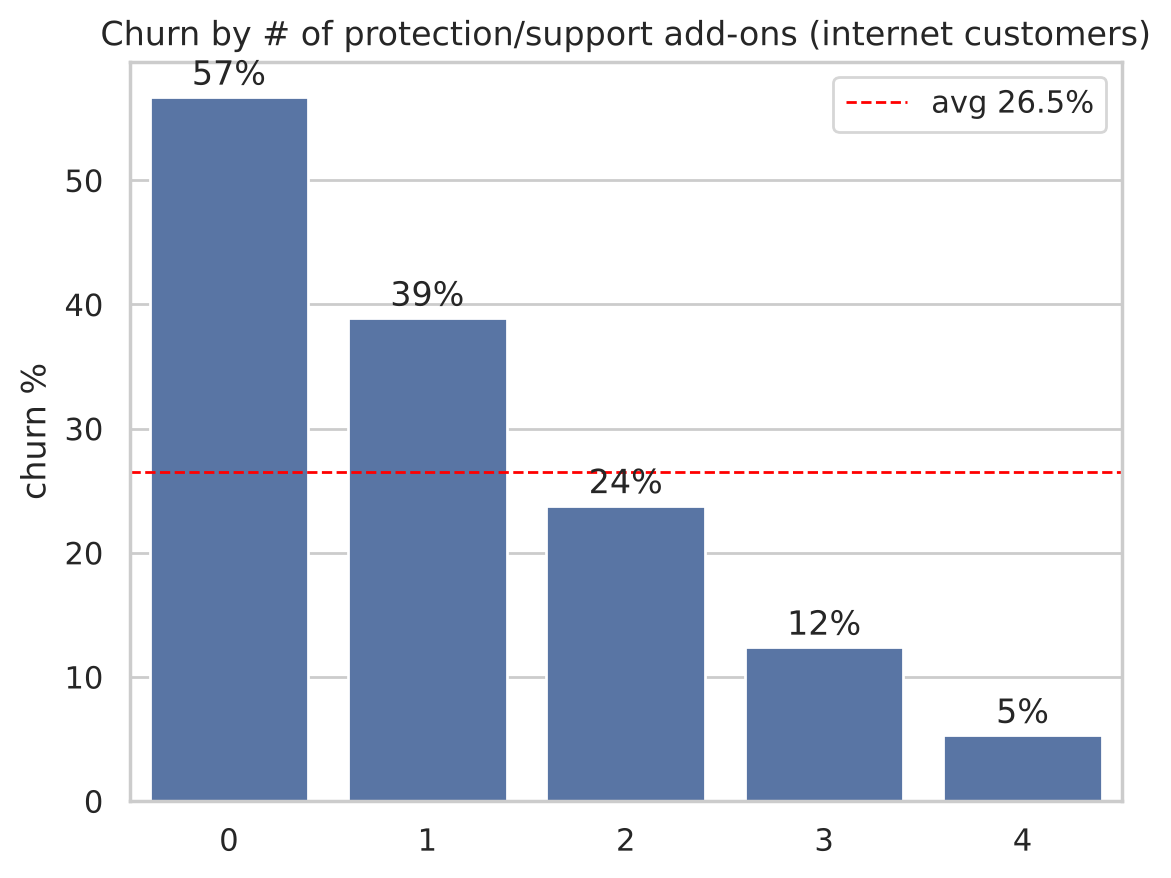

In [17]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
inet = df[df.InternetService != "No"].copy()
inet["n_protect_addons"] = (inet[addons] == "Yes").sum(axis=1)
t = inet.groupby("n_protect_addons")["churn"].agg(churn_rate="mean", customers="size").round(3)
display(t)
print(f"chi2 p-value = {chi2_contingency(pd.crosstab(inet.n_protect_addons, inet.churn))[1]:.2e}")
for a in ["TechSupport", "OnlineSecurity"]:
    r = inet.groupby(a, observed=True)["churn"].mean()
    print(f"{a}: No={r['No']:.1%}  Yes={r['Yes']:.1%}")
bar(t, "Churn by # of protection/support add-ons (internet customers)"); plt.show()

Among internet customers, zero add-ons means about **57%** churn and all four means about **5%**. `TechSupport` and `OnlineSecurity` alone cut churn by roughly two thirds.

**Action:** a free 3-month trial of TechSupport / OnlineSecurity for new Fiber customers. Caveat: customers who buy add-ons are probably more committed to begin with, so the causal effect needs an experiment.

### Segment overview ranked by effect size

In [18]:
rows = []
for col in ["Contract", "PaymentMethod", "InternetService", "tenure_band", "TechSupport",
            "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Dependents", "Partner"]:
    g = df.groupby(col, observed=True)["churn"].agg(["mean", "size"])
    rows.append({"feature": col, "worst_segment": g["mean"].idxmax(), "worst_rate": g["mean"].max(),
                 "best_segment": g["mean"].idxmin(), "best_rate": g["mean"].min(),
                 "spread_pp": (g["mean"].max() - g["mean"].min()) * 100})
pd.DataFrame(rows).sort_values("spread_pp", ascending=False).round(3).reset_index(drop=True)

,feature,worst_segment,worst_rate,best_segment,best_rate,spread_pp
0,tenure_band,0-6m,0.529,49-72m,0.095,43.424
1,Contract,Month-to-month,0.427,Two year,0.028,39.878
2,InternetService,Fiber optic,0.419,No,0.074,34.488
3,OnlineSecurity,No,0.418,No internet service,0.074,34.362
4,TechSupport,No,0.416,No internet service,0.074,34.230
5,PaymentMethod,Electronic check,0.453,Credit card (automatic),0.152,30.042
6,SeniorCitizen,Yes,0.417,No,0.236,18.075
7,PaperlessBilling,Yes,0.336,No,0.163,17.235
8,Dependents,No,0.313,Yes,0.155,15.829
9,Partner,No,0.330,Yes,0.197,13.293


## 6) Caveats and next steps

- **Correlation is not causation.** These variables overlap heavily (month-to-month contracts, electronic checks, Fiber and short tenure cluster in the same customers). Next step: a multivariate model (Logistic Regression or Gradient Boosting with SHAP) to estimate each factor's effect *after* controlling for the others.
- **Snapshot data.** There are no churn dates or price-change histories, so a rigorous survival analysis and seasonality checks are not possible.
- **Missing business context.** Complaints, network quality, support interactions and competitor pricing are not in the data, and they likely explain much of the Fiber churn.
- **Validation.** Any retention offer should be A/B tested against a control group before rollout.

### Guard: do the numbers quoted in the summary still match the data?

In [19]:
checks = {
    "overall churn ~26.5%": abs(BASE - 0.265) < 0.005,
    "revenue share ~30%": abs(mrr_lost / mrr_total - 0.305) < 0.01,
    "month-to-month ~43%": abs(df[df.Contract == "Month-to-month"].churn.mean() - 0.427) < 0.005,
    "two-year ~3%": abs(df[df.Contract == "Two year"].churn.mean() - 0.028) < 0.005,
    "first 6 months ~53%": abs(df[df.tenure <= 6].churn.mean() - 0.529) < 0.005,
    "electronic check ~45%": abs(df[df.PaymentMethod == "Electronic check"].churn.mean() - 0.453) < 0.005,
    "Fiber ~42%": abs(df[df.InternetService == "Fiber optic"].churn.mean() - 0.419) < 0.005,
    "Fiber + month-to-month ~55%": abs(seg.churn.mean() - 0.546) < 0.005,
    "0 add-ons ~57%": abs(t.loc[0, "churn_rate"] - 0.567) < 0.005,
    "4 add-ons ~5%": abs(t.loc[4, "churn_rate"] - 0.053) < 0.005,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values()), "Summary numbers are out of sync with the data - update section 0"


PASS overall churn ~26.5%
PASS revenue share ~30%
PASS month-to-month ~43%
PASS two-year ~3%
PASS first 6 months ~53%
PASS electronic check ~45%
PASS Fiber ~42%
PASS Fiber + month-to-month ~55%
PASS 0 add-ons ~57%
PASS 4 add-ons ~5%
